In [30]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yaml


In [31]:
# Find saved runs and calculate statistics directly from their daily results.
project_root = Path(".") if Path("results").is_dir() else Path("..")
run_directory = project_root / "results"

records = []
for results_path in sorted(run_directory.glob("*/*/seed_*/validation_results.csv")):
    model, data_source, seed_folder = results_path.relative_to(run_directory).parts[:3]
    results = pd.read_csv(results_path, parse_dates=["date"]).set_index("date").sort_index()
    config = yaml.safe_load((results_path.parent / "experiment_config.yaml").read_text())
    trading_days = config["environment"].get("trading_days_per_year", 252)
    returns = results["net_return"]
    wealth = (1 + returns).cumprod()
    volatility = returns.std()
    records.append({
        "experiment": model,
        "data_source": data_source,
        "seed": int(seed_folder.removeprefix("seed_")),
        "cumulative net return": wealth.iloc[-1] - 1,
        "annualized net return": wealth.iloc[-1] ** (trading_days / len(returns)) - 1,
        "annualized volatility": volatility * np.sqrt(trading_days),
        "Sharpe ratio": returns.mean() / volatility * np.sqrt(trading_days),
        "maximum drawdown": (wealth / wealth.cummax().clip(lower=1.0) - 1).min(),
        "annualized turnover": results["turnover"].mean() * trading_days,
        "average gross exposure": results["gross_exposure"].mean(),
        "maximum gross exposure": results["gross_exposure"].max(),
        "average short exposure": results["short_exposure"].mean(),
        "annualized implementation cost": (
            results["transaction_cost"] + results["short_borrow_cost"]
        ).mean() * trading_days,
    })

if not records:
    raise ValueError("No validation_results.csv files found under results/.")
summary = pd.DataFrame(records)
average_summary = (
    summary.drop(columns="seed")
    .groupby(["experiment", "data_source"])
    .mean(numeric_only=True)
)


In [32]:
# Use the same source, dates, and trading costs as the saved runs.
reference = summary.iloc[0]
reference_directory = (
    run_directory / reference["experiment"] / reference["data_source"]
    / f"seed_{reference['seed']}"
)
config = yaml.safe_load((reference_directory / "experiment_config.yaml").read_text())
dates = pd.read_csv(reference_directory / "validation_results.csv", parse_dates=["date"])["date"]
market_returns = (
    pd.read_csv(config["data"]["feature_path"], parse_dates=["date"])
    .pivot(index="date", columns="symbol", values="return_1d")
    .loc[dates]
)
symbols = config["data"]["tradable_symbols"]
rebalance_days = config["environment"]["decision_frequency_days"]
cost_rate = config["environment"]["transaction_cost_rate"]
trading_days = config["environment"].get("trading_days_per_year", 252)

# Equal weight: start invested, drift daily, and rebalance at the chosen interval.
equal_weights = np.full(len(symbols), 1 / len(symbols))
weights = equal_weights.copy()
equal_returns, equal_turnover = [], []
for day, asset_returns in enumerate(market_returns[symbols].to_numpy()):
    turnover = 0.0
    if day > 0 and day % rebalance_days == 0:
        turnover = np.abs(equal_weights - weights).sum()
        weights = equal_weights.copy()
    gross_return = float(weights @ asset_returns)
    equal_returns.append(gross_return - cost_rate * turnover)
    equal_turnover.append(turnover)
    weights = weights * (1 + asset_returns) / (1 + gross_return)

# SPY is buy-and-hold with no entry or ongoing trading costs.
benchmark_returns = pd.DataFrame(
    {"SPY": market_returns["SPY"], "equal_weight": equal_returns},
    index=market_returns.index,
)
benchmark_turnover = pd.DataFrame(
    {"SPY": 0.0, "equal_weight": equal_turnover}, index=market_returns.index,
)
for name, returns in benchmark_returns.items():
    wealth = (1 + returns).cumprod()
    volatility = returns.std()
    average_summary.loc[(name, reference["data_source"]), :] = pd.Series({
        "cumulative net return": wealth.iloc[-1] - 1,
        "annualized net return": wealth.iloc[-1] ** (trading_days / len(returns)) - 1,
        "annualized volatility": volatility * np.sqrt(trading_days),
        "Sharpe ratio": returns.mean() / volatility * np.sqrt(trading_days),
        "maximum drawdown": (wealth / wealth.cummax().clip(lower=1.0) - 1).min(),
        "annualized turnover": benchmark_turnover[name].mean() * trading_days,
        "average gross exposure": 1.0,
        "maximum gross exposure": 1.0,
        "average short exposure": 0.0,
        "annualized implementation cost": benchmark_turnover[name].mean() * cost_rate * trading_days,
    })

display(average_summary.round(3))


,,cumulative net return,annualized net return,annualized volatility,Sharpe ratio,maximum drawdown,annualized turnover,average gross exposure,maximum gross exposure,average short exposure,annualized implementation cost
experiment,data_source,,,,,,,,,,
long_only,historical,1.452,0.190,0.236,0.848,-0.369,26.658,1.000,1.000,0.000,0.013
long_short_scaled,historical,1.642,0.210,0.222,0.975,-0.308,17.341,1.588,1.644,0.294,0.012
long_short_unscaled,historical,1.253,0.173,0.217,0.842,-0.322,43.644,1.600,1.649,0.300,0.025
SPY,historical,1.162,0.164,0.207,0.835,-0.337,0.000,1.000,1.000,0.000,0.000
equal_weight,historical,1.029,0.149,0.204,0.785,-0.369,0.720,1.000,1.000,0.000,0.000


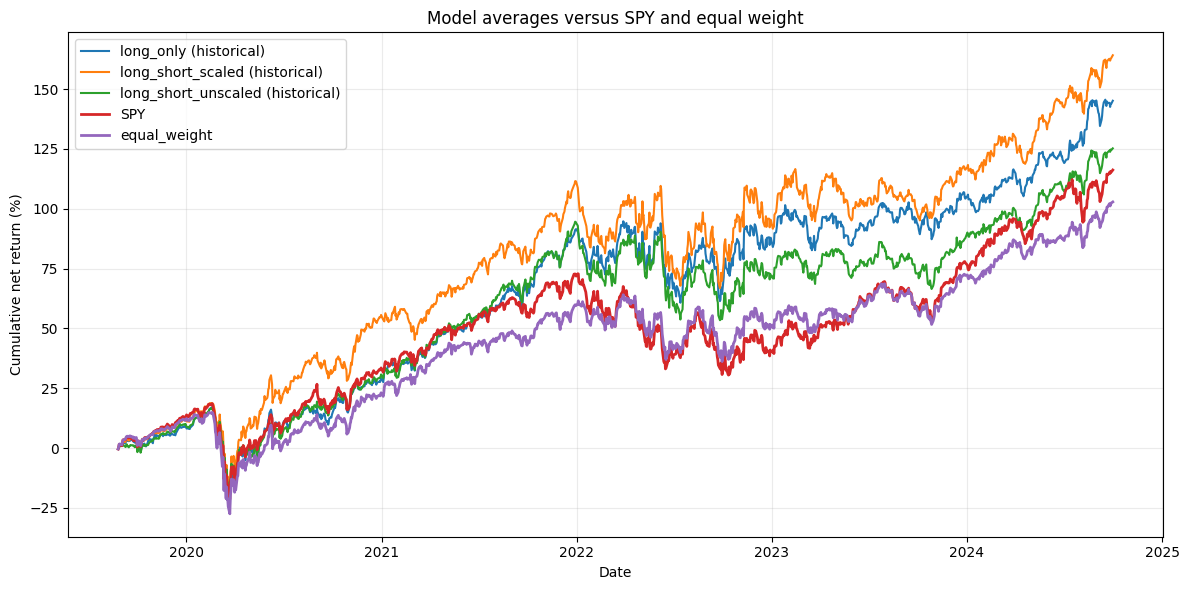

In [33]:
fig, ax = plt.subplots(figsize=(12, 6))
return_histories = {}

for (model, data_source), runs in summary.groupby(["experiment", "data_source"]):
    cumulative_returns = []
    for run in runs.itertuples():
        results_path = (
            run_directory / run.experiment / run.data_source
            / f"seed_{run.seed}" / "validation_results.csv"
        )
        results = pd.read_csv(results_path, parse_dates=["date"]).set_index("date")
        cumulative_returns.append(((1 + results["net_return"]).cumprod() - 1) * 100)

    mean_returns = pd.concat(cumulative_returns, axis=1).mean(axis=1)
    return_histories[f"{model} ({data_source})"] = mean_returns
    ax.plot(mean_returns.index, mean_returns, label=f"{model} ({data_source})")

for name, returns in benchmark_returns.items():
    cumulative_returns = ((1 + returns).cumprod() - 1) * 100
    return_histories[name] = cumulative_returns
    ax.plot(cumulative_returns.index, cumulative_returns, label=name, linewidth=2)

ax.set_title("Model averages versus SPY and equal weight")
ax.set_ylabel("Cumulative net return (%)")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


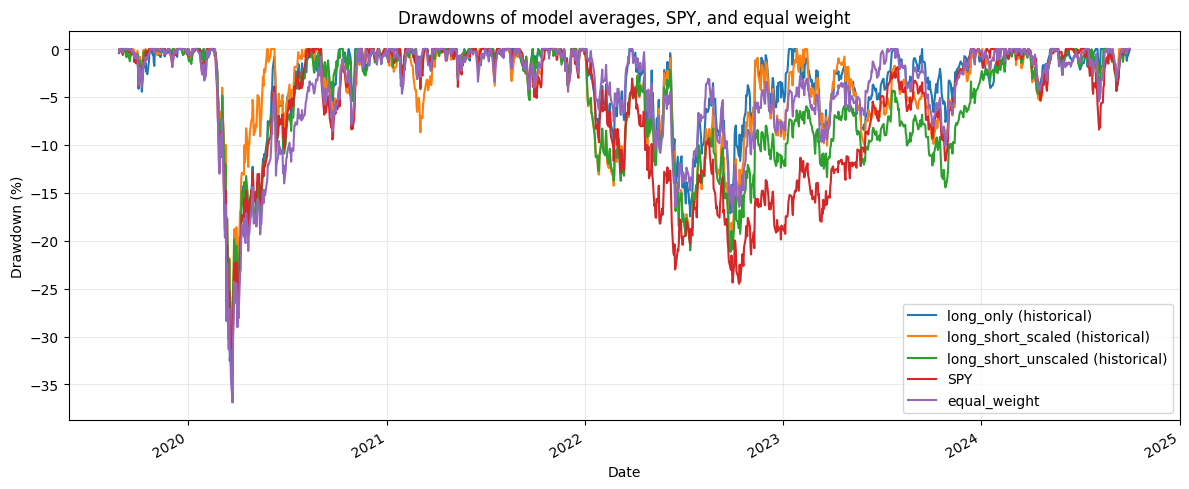

In [34]:
# Calculate drawdown from the same average return curves plotted above.
wealth = 1 + pd.DataFrame(return_histories) / 100
drawdowns = (wealth / wealth.cummax().clip(lower=1.0) - 1) * 100

ax = drawdowns.plot(figsize=(12, 5))
ax.set_title("Drawdowns of model averages, SPY, and equal weight")
ax.set_ylabel("Drawdown (%)")
ax.set_xlabel("Date")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


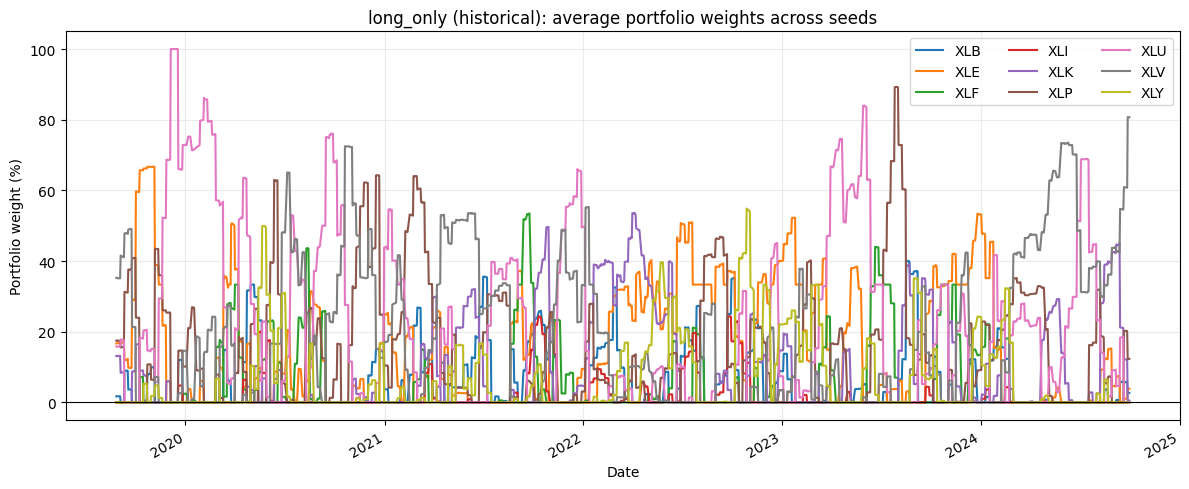

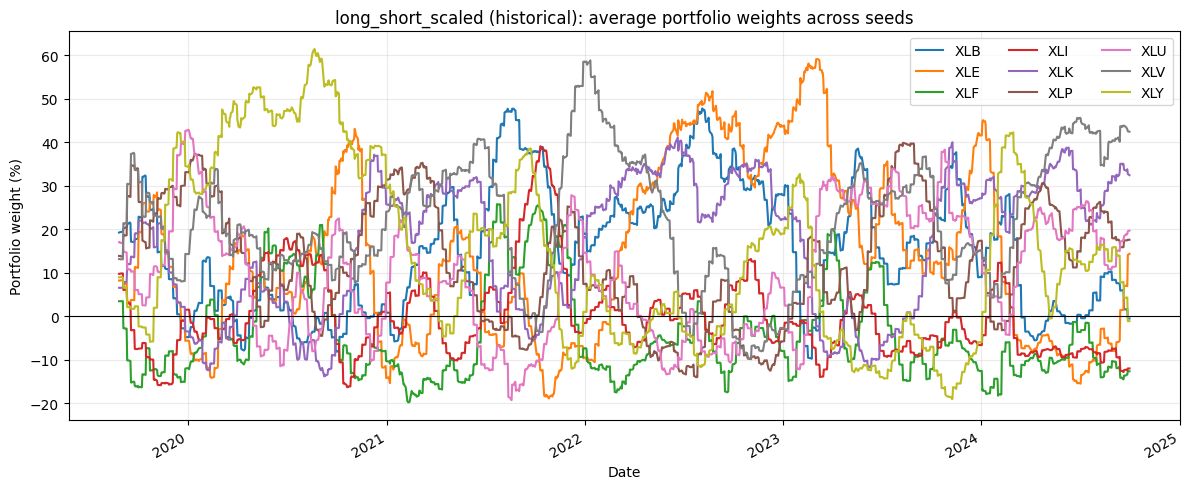

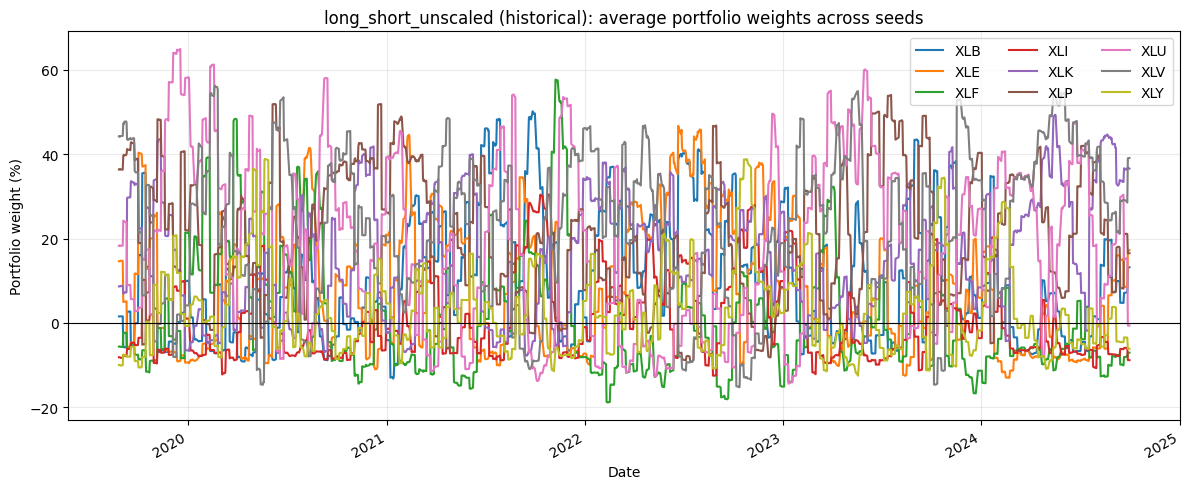

In [35]:
for (model, data_source), runs in summary.groupby(["experiment", "data_source"]):
    weight_histories = []
    for run in runs.itertuples():
        results_path = (
            run_directory / run.experiment / run.data_source
            / f"seed_{run.seed}" / "validation_results.csv"
        )
        results = pd.read_csv(results_path, parse_dates=["date"]).set_index("date")
        weight_histories.append(results.filter(like="weight_"))

    mean_weights = pd.concat(weight_histories).groupby(level=0).mean()
    mean_weights = mean_weights.rename(columns=lambda name: name.removeprefix("weight_"))
    ax = (mean_weights * 100).plot(figsize=(12, 5))
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"{model} ({data_source}): average portfolio weights across seeds")
    ax.set_ylabel("Portfolio weight (%)")
    ax.set_xlabel("Date")
    ax.grid(alpha=0.25)
    ax.legend(ncol=3)
    plt.tight_layout()
    plt.show()
